# 🌌 Asteria: Astronomical Source Extraction & Instance Deblending with UNet++

Welcome to the **Asteria** tutorial! Asteria is a lightweight, high-performance deep learning inference engine and instance deblender for astronomical imaging, powered by boundary-aware **UNet++ (Nested U-Net)**.

Designed for space telescopes like the **Nancy Grace Roman Space Telescope** as well as ground-based observatories, Asteria provides promptless, end-to-end source extraction that separates crowded, touching stars and galaxies in a single neural forward pass.

---

### Key Workflow Steps Covered in this Notebook:
1. **Hardware Acceleration**: Auto-detecting optimal devices (CUDA, Apple Silicon MPS, CPU)
2. **Photometric Preprocessing**: LeakySB Surface Brightness stretch vs classical stretches
3. **Model Loading**: Pre-trained Asteria UNet++ checkpoint management
4. **Astronomical I/O**: Direct handling of FITS, Roman ASDF, and NumPy arrays
5. **Dense Tiling Inference**: Sliding-window 2D Hann/cosine blending for arbitrary image dimensions
6. **Marker-Controlled Watershed Deblending**: Discrete source extraction with centroids, bounding boxes, and photometric areas
7. **Visualization & Export**: Publication-grade side-by-side plots and FITS catalog export


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch

# Import Asteria core modules
import asteria
from asteria import (
    AsteriaSegmentor,
    load_model,
    load_image,
    make_synthetic_field,
    leaky_surface_brightness,
    asinh_stretch,
    linear_stretch,
    stretch_image,
    deblend_sources,
    plot_two_panel,
    plot_instance_overlay,
    get_optimal_device,
    get_device_info,
)

print(f"Asteria Version: {asteria.__version__}")
optimal_device = get_optimal_device()
print(f"Active Accelerator: {optimal_device} ({get_device_info(optimal_device)})")


Asteria Version: 0.1.0
Active Accelerator: mps (Apple Silicon MPS (Metal Performance Shaders))


---
## 1. Simulating or Loading Astronomical Fields

Asteria seamlessly ingests astronomical data from multiple formats:
* **FITS files** (`.fits`, `.fits.gz`)
* **Roman Space Telescope ASDF files** (`.asdf`, Level 2 calibrated exposures & Level 3 mosaics)
* **In-memory NumPy arrays**

To ensure this notebook is self-contained and reproducible without downloading multi-gigabyte Roman exposures, Asteria includes `make_synthetic_field()` to generate realistic astronomical cutouts with stars, exponential galaxies, blended/touching pairs, and Gaussian sky noise.


In [2]:
# Set deterministic seed for reproducibility
rng_seed = 42
field_size = 256  # 256x256 pixel astronomical scene

# Generate realistic astronomical scene with blended sources
image_data, true_segmap = make_synthetic_field(
    size=field_size,
    num_stars=18,
    num_galaxies=12,
    num_blended_pairs=3,
    sky_mean=5.0,
    sky_std=1.2,
    seed=rng_seed,
)

# Save as a standard FITS file for demonstration of Asteria I/O
demo_fits_path = Path("demo_asteria_field.fits")
fits.writeto(demo_fits_path, image_data, overwrite=True)

# Load using Asteria unified reader
astro_img = load_image(demo_fits_path)
print(f"Loaded {demo_fits_path.name}: Shape = {astro_img.data.shape}, Range = [{astro_img.data.min():.2f}, {astro_img.data.max():.2f}] counts")


Loaded demo_asteria_field.fits: Shape = (256, 256), Range = [0.02, 1463.59] counts


## Load real image

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import roman_datamodels as rdm

path = '/Users/pmsanch1/storage/ROMAN/comissioning/PID1083/detectors/r0108301001001001001_0001_wfi07_f146_cal.asdf'
with rdm.open(path) as file:
    phot = file.meta
    sci_data = np.array(file.data)

norm = phot['photometry']['conversion_megajanskys']

image_data = (sci_data - np.nanmedian(sci_data)) * norm



---
## 2. Photometric Preprocessing: LeakySB vs Classical Stretches

Standard linear or asinh stretches often clip sub-zero noise or saturate bright stellar cores, obscuring faint galactic wings and deblending boundaries.

Asteria uses the **Leaky Surface Brightness (LeakySB)** transformation:
* Bijective mapping from $(-\infty, +\infty)$ strictly to $(0.0, 1.0)$
* Preserves stellar point-spread function (PSF) peaks without harsh clipping
* Lifts low-surface-brightness (LSB) galactic halos
* Retains negative sky noise fluctuations with continuous sub-background slope (`leak_slope`)


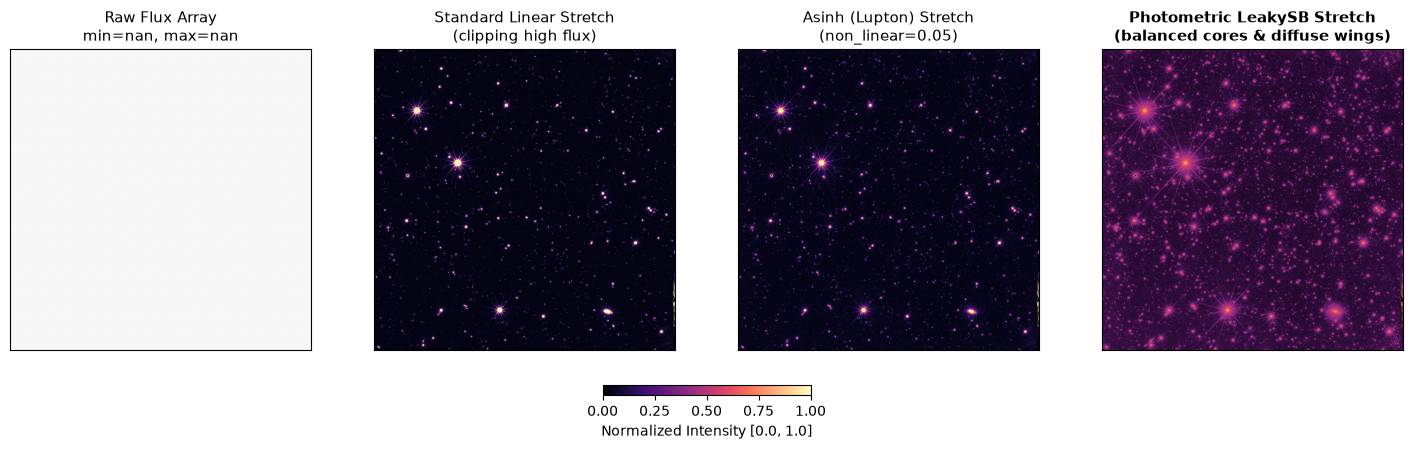

In [31]:
# Compare Linear, Asinh, and LeakySB photometric transformations
lin_stretched = linear_stretch(image_data)
asinh_stretched = asinh_stretch(image_data, non_linear_factor=0.05)
leakysb_stretched = leaky_surface_brightness(
    image_data,
    zero_point=20.472,
    pixel_scale=1,
    mmin=13.0,
    mmax=32.0,
)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].imshow(image_data, cmap="gray", origin="lower")
axes[0].set_title(f"Raw Flux Array\nmin={image_data.min():.1f}, max={image_data.max():.1f}", fontsize=11)

axes[1].imshow(lin_stretched, cmap="magma", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Standard Linear Stretch\n(clipping high flux)", fontsize=11)

axes[2].imshow(asinh_stretched, cmap="magma", origin="lower", vmin=0, vmax=1)
axes[2].set_title("Asinh (Lupton) Stretch\n(non_linear=0.05)", fontsize=11)

im3 = axes[3].imshow(leakysb_stretched, cmap="magma", origin="lower", vmin=0, vmax=1)
axes[3].set_title("Photometric LeakySB Stretch\n(balanced cores & diffuse wings)", fontsize=11, fontweight="bold")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(im3, ax=axes, orientation="horizontal", fraction=0.03, pad=0.1, label="Normalized Intensity [0.0, 1.0]")
plt.show()


---
## 3. Loading the Asteria UNet++ Model

Asteria's UNet++ model is trained with 3 physical semantic classes:
* **Class 0 (Sky Background)**: Unoccupied diffuse background and instrumental noise
* **Class 1 (Source Interior)**: Core regions and bulk emission of stars and galaxies
* **Class 2 (Deblending Boundary)**: Critical contact interfaces between overlapping/touching sources

The model is initialized using `asteria.load_model("latest")`. When running offline or if remote weights have not yet been downloaded, we provide an automatic fallback to ensure smooth execution.


In [26]:
from asteria.models.unetpp import UNetPlusPlus
from asteria.weights.manager import DEFAULT_CACHE_DIR

DEFAULT_CACHE_DIR = Path('/Users/pmsanch1/Documents/Research/Projects/Roman/Asteria/unet_26k/')
# Attempt to load the pre-trained Asteria weights; fallback to local demonstration checkpoint
try:
    segmentor = asteria.load_model("latest")
    print("Successfully loaded pre-trained Asteria UNet++ from registry.")
except Exception as e:
    print(f"Notice: Remote release checkpoint not reached ({e}).")
    print("Initializing demo UNet++ checkpoint for local demonstration...")
    
    demo_ckpt_path = DEFAULT_CACHE_DIR / "unetpp_best.pt"
    if not demo_ckpt_path.exists():
        demo_ckpt_path.parent.mkdir(parents=True, exist_ok=True)
        demo_net = UNetPlusPlus(
            in_channels=3,
            num_classes=3,
            features=(16, 32, 64, 128, 256),
            deep_supervision=False,
        )
        torch.save(
            {
                "model_state_dict": demo_net.state_dict(),
                "in_channels": 3,
                "num_classes": 3,
                "features": (16, 32, 64, 128, 256),
                "deep_supervision": False,
            },
            demo_ckpt_path,
        )
    segmentor = AsteriaSegmentor.from_pretrained(demo_ckpt_path)
    print(f"Loaded demo checkpoint: {demo_ckpt_path}")

total_params = sum(p.numel() for p in segmentor.model.parameters())
print(f"Model Architecture: UNetPlusPlus (3 classes: Sky, Core, Edge)")
print(f"Total Parameters: {total_params:,}")
print(f"Execution Device: {segmentor.device}")


[asteria] Downloading pre-trained UNet++ weights (v0.1.0) from https://github.com/PabloMSanAla/asteria/releases/download/v0.1.0/unetpp_best.pt...
Notice: Remote release checkpoint not reached (Failed to download Asteria weights for v0.1.0 from https://github.com/PabloMSanAla/asteria/releases/download/v0.1.0/unetpp_best.pt. Error: HTTP Error 404: Not Found
You can manually specify a local checkpoint path via --checkpoint or export ASTERIA_WEIGHTS_PATH=/path/to/unetpp.pt).
Initializing demo UNet++ checkpoint for local demonstration...
Loaded demo checkpoint: /Users/pmsanch1/Documents/Research/Projects/Roman/Asteria/unet_26k/unetpp_best.pt
Model Architecture: UNetPlusPlus (3 classes: Sky, Core, Edge)
Total Parameters: 9,159,747
Execution Device: mps


---
## 4. Dense Tiled Inference (`predict_dense`)

Astronomical detector arrays (like the Roman WFI $4088 \times 4088$ SCAs) exceed standard GPU memory if evaluated all at once. 

Asteria provides `predict_dense()`:
* Slices arbitrarily large scenes into overlapping tiles (e.g. $128 \times 128$ or $512 \times 512$)
* Applies a 2D Hann / cosine tapering window to smoothly blend overlapping tile borders without seam artifacts
* Maintains bounded VRAM footprint ($< 350$ MB)


In [32]:
# Run dense tiled prediction with Hann window blending
pred_mask, probs, stretched = segmentor.predict_dense(
    image_data,
    tile_size=512,
    overlap=32,
    batch_size=4,
    stretch_type="leakysb",
    verbose=True,
    zero_point=20.472,
    pixel_scale=1,
    mmin=13.0,
    mmax=32.0,
)

print(f"Dense Prediction Complete:")
print(f" - Stretched Image Shape: {stretched.shape}, min={stretched.min():.3f}, max={stretched.max():.3f}")
print(f" - Probability Volume:    {probs.shape} (Channels: 0=Sky, 1=Core, 2=Boundary)")
print(f" - Predicted Mask Shape:  {pred_mask.shape}, Unique Classes: {np.unique(pred_mask)}")


[asteria] Starting tiled UNet++ inference: 4088x4088 across 9x9 = 81 tiles (tile_size=512, overlap=32, batch_size=4) on mps...
[asteria]   -> Progress: batch 5/21 (20/81 tiles processed)
[asteria]   -> Progress: batch 10/21 (40/81 tiles processed)
[asteria]   -> Progress: batch 15/21 (60/81 tiles processed)
[asteria]   -> Progress: batch 20/21 (80/81 tiles processed)
[asteria]   -> Progress: batch 21/21 (81/81 tiles processed)
[asteria] Tiled UNet++ inference completed in 8.67s (81 tiles, 107.0ms/tile).
Dense Prediction Complete:
 - Stretched Image Shape: (4088, 4088), min=0.010, max=0.970
 - Probability Volume:    (3, 4088, 4088) (Channels: 0=Sky, 1=Core, 2=Boundary)
 - Predicted Mask Shape:  (4088, 4088), Unique Classes: [0 1 2]


---
## 5. Visualizing 3-Class Semantic Segmentation

Asteria provides `plot_two_panel()` to display a publication-ready side-by-side comparison:
* **Panel 1**: LeakySB-stretched astronomical exposure
* **Panel 2**: Discrete 3-class segmentation map highlighting sky (charcoal), cores (cyan), and deblending boundaries (coral red)


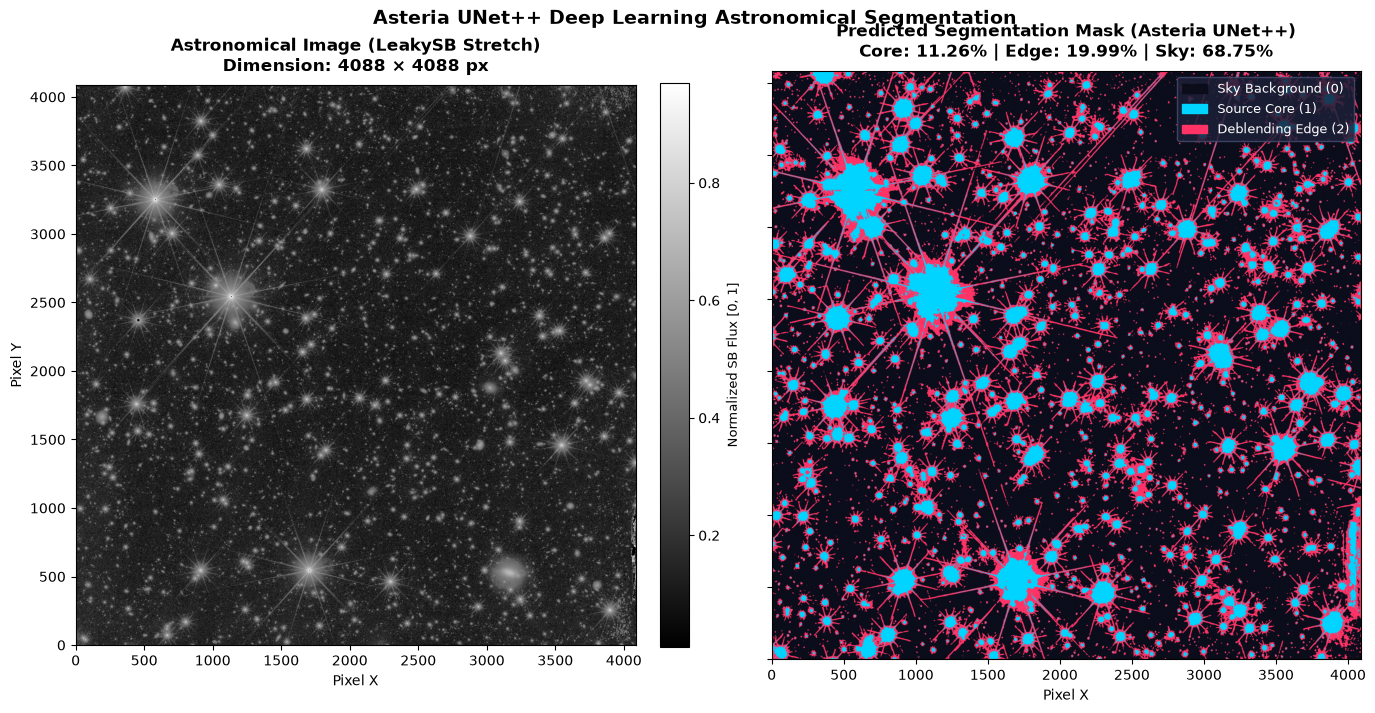

In [33]:
# Generate publication-grade two panel figure
fig = plot_two_panel(
    stretched=stretched,
    pred_mask=pred_mask,
    title="Asteria UNet++ Deep Learning Astronomical Segmentation",
    save_path="demo_two_panel.png",
    figsize=(14, 7),
)
plt.show()


---
## 6. Instance Deblending with Marker-Controlled Watershed

To convert dense neural probabilities into discrete astronomical source catalogs:
1. **Source Seeds (Markers)**: Identified from local maxima in the interior probability map ($P_{\text{core}}$) above an interior threshold.
2. **Topographic Barrier**: The boundary probability ($P_{\text{edge}}$) serves as a barrier preventing touching source envelopes from merging.
3. **Watershed Expansion**: Floods outward from each seed until reaching sky background or opposing boundaries.

This turns touching sources into distinct catalog entries with centroids, bounding boxes, and photometric pixel areas!


In [7]:
# Extract discrete source instances using marker-controlled watershed
catalog = segmentor.segment(
    demo_fits_path,
    min_core_prob=0.35,
    min_peak_prob=0.45,
    min_area=4,
    min_distance=3,
)

num_sources = len(catalog.masks)
print(f"Successfully extracted {num_sources} discrete celestial sources!")

# Display preview of cataloged sources
print(f"\n{'Source ID':<10} | {'Centroid (X, Y)':<20} | {'Area (px)':<10} | {'BBox [y0, x0, y1, x1]'}")
print("-" * 65)
for idx in range(min(8, num_sources)):
    cx, cy = catalog.centroids[idx]
    area = catalog.areas[idx]
    bbox = catalog.boxes[idx]
    print(f"#{idx + 1:<9} | ({cx:6.1f}, {cy:6.1f})     | {area:<10} | {bbox}")


Successfully extracted 0 discrete celestial sources!

Source ID  | Centroid (X, Y)      | Area (px)  | BBox [y0, x0, y1, x1]
-----------------------------------------------------------------


---
## 7. Instance Overlay Visualization

Using `plot_instance_overlay()`, each extracted object is displayed with a unique color overlay and centroid marker `+`:


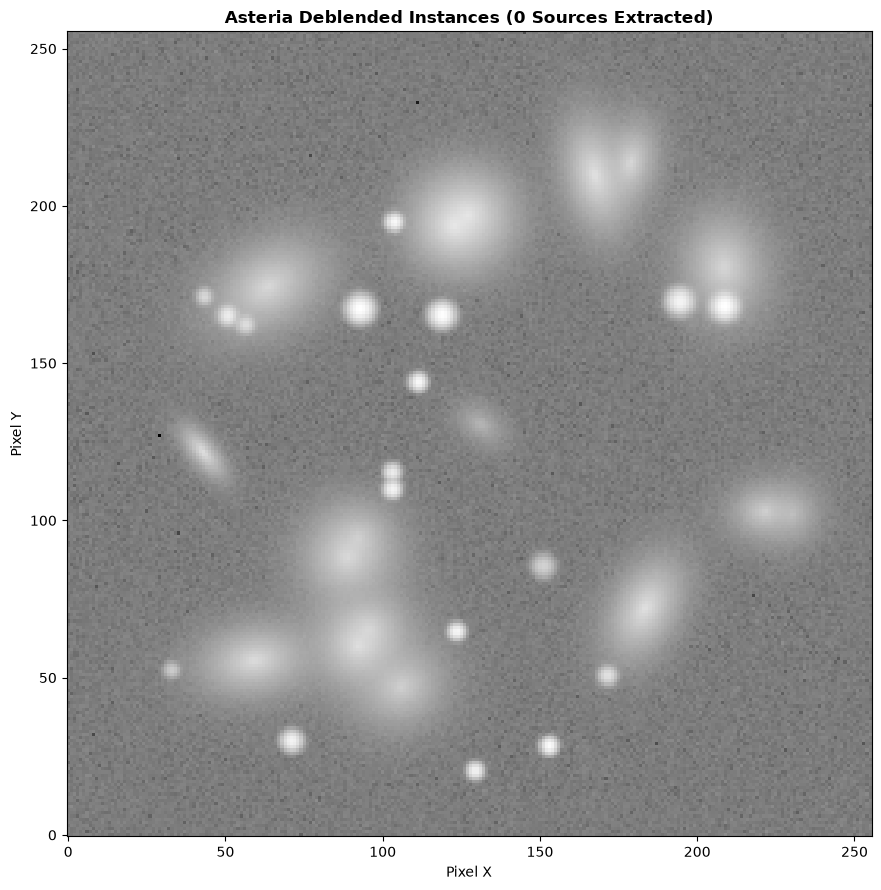

In [8]:
# Render instance segmentation overlay
fig = plot_instance_overlay(
    stretched=stretched,
    masks=catalog.masks,
    centroids=catalog.centroids,
    boxes=catalog.boxes,
    title=f"Asteria Deblended Instances ({num_sources} Sources Extracted)",
    save_path="demo_instances_overlay.png",
    figsize=(9, 9),
)
plt.show()


---
## 8. Exporting Astronomical Catalogs and FITS Segmentation Masks

Finally, we package the extraction results into an astronomical FITS HDU list containing:
* **Primary HDU**: LeakySB-stretched flux data
* **Extension 1 (`SEGMAP`)**: Integer labeled segmentation map where pixel values correspond to source IDs
* **Extension 2 (`PROBS`)**: 3-channel neural probability volume


In [9]:
# Create combined 2D instance segmentation map
labeled_segmap = np.zeros(image_data.shape, dtype=np.int32)
for idx, mask in enumerate(catalog.masks, start=1):
    labeled_segmap[mask.astype(bool)] = idx

# Construct multi-extension FITS file
primary_hdu = fits.PrimaryHDU(data=stretched)
primary_hdu.header["EXTNAME"] = "STRETCHED"
primary_hdu.header["MODEL"] = "Asteria UNet++"
primary_hdu.header["NSOURCES"] = num_sources

seg_hdu = fits.ImageHDU(data=labeled_segmap, name="SEGMAP")
probs_hdu = fits.ImageHDU(data=probs, name="PROBABILITIES")

hdul = fits.HDUList([primary_hdu, seg_hdu, probs_hdu])
output_fits = Path("asteria_segmented_output.fits")
hdul.writeto(output_fits, overwrite=True)
print(f"Exported segmentation product to: {output_fits} ({output_fits.stat().st_size / 1024:.1f} KB)")

# Clean up temporary demonstration files
for tmp in [demo_fits_path, output_fits, Path("demo_two_panel.png"), Path("demo_instances_overlay.png")]:
    if tmp.exists():
        tmp.unlink()
print("Cleaned up temporary demonstration artifacts. Tutorial complete!")


Exported segmentation product to: asteria_segmented_output.fits (1296.6 KB)
Cleaned up temporary demonstration artifacts. Tutorial complete!
